## Delivery ETA Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("delivery_eta_prediction.csv")

df.head()

,Distance_km,Traffic,Weather,Vehicle,Order_Size,Delivery_Time_Minutes
0,9.68,High,Clear,Bike,3,58.4
1,23.79,Low,Clear,Scooter,9,84.5
2,18.43,Low,Clear,Bike,2,60.8
3,15.17,Medium,Clear,Bike,3,61.4
4,4.32,Medium,Rain,Bike,2,43.4


In [3]:
df.shape

(1200, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Distance_km            1200 non-null   float64
 1   Traffic                1200 non-null   object 
 2   Weather                1200 non-null   object 
 3   Vehicle                1200 non-null   object 
 4   Order_Size             1200 non-null   int64  
 5   Delivery_Time_Minutes  1200 non-null   float64
dtypes: float64(2), int64(1), object(3)
memory usage: 56.4+ KB


In [5]:
df.isnull().sum()

Distance_km              0
Traffic                  0
Weather                  0
Vehicle                  0
Order_Size               0
Delivery_Time_Minutes    0
dtype: int64

In [6]:
print(df["Traffic"].value_counts())
print(df["Weather"].value_counts())
print(df["Vehicle"].value_counts())

Traffic
Medium    552
Low       358
High      290
Name: count, dtype: int64
Weather
Clear    772
Rain     315
Fog      113
Name: count, dtype: int64
Vehicle
Bike       433
Scooter    366
Car        240
Van        161
Name: count, dtype: int64


In [7]:
X = df.drop("Delivery_Time_Minutes", axis=1)
y = df["Delivery_Time_Minutes"]

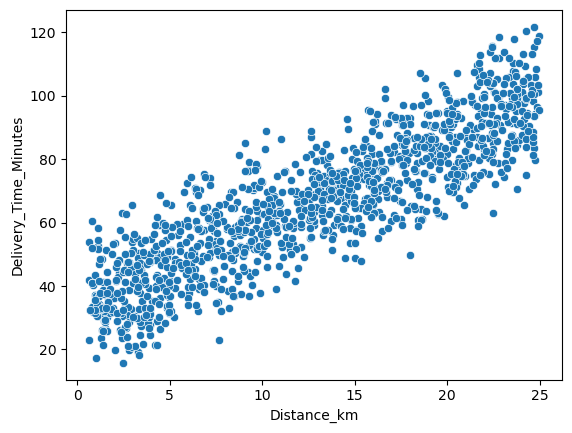

In [8]:
sns.scatterplot(data=df, x="Distance_km", y="Delivery_Time_Minutes")
plt.show()

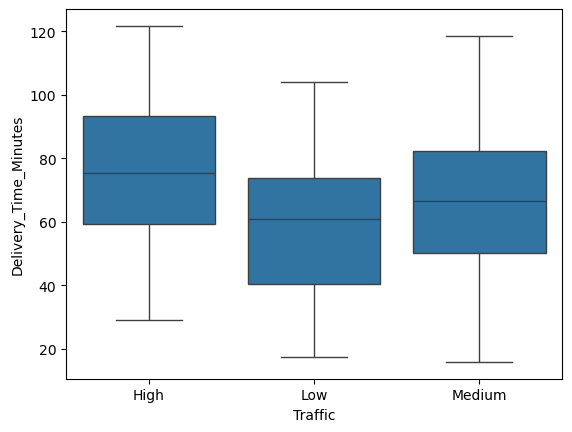

In [9]:
sns.boxplot(data=df, x="Traffic", y="Delivery_Time_Minutes")
plt.show()

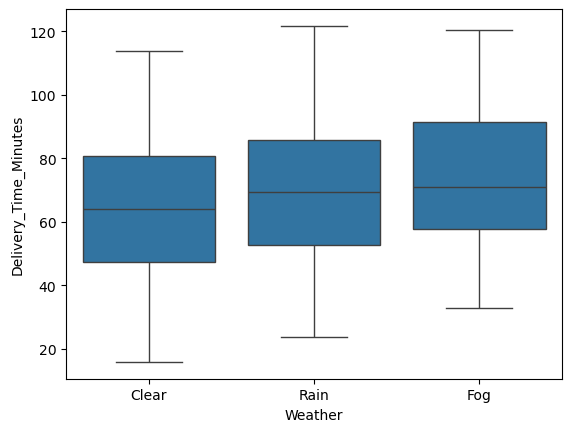

In [10]:
sns.boxplot(data=df, x="Weather", y="Delivery_Time_Minutes")
plt.show()

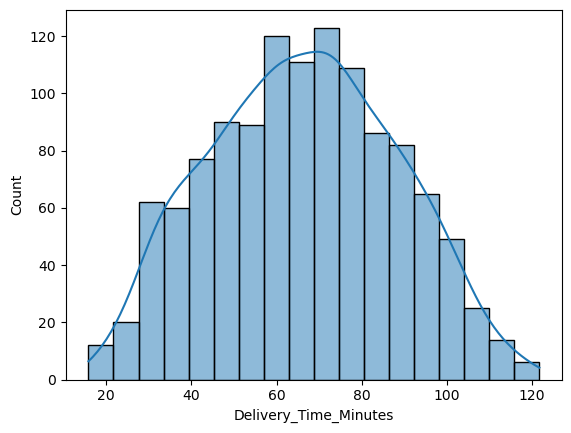

In [11]:
sns.histplot(df["Delivery_Time_Minutes"], kde=True)
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [13]:
numeric_features = X.select_dtypes(exclude="object").columns
categorical_features = X.select_dtypes(include="object").columns

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [17]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [18]:
y_pred = model.predict(X_test)

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 3.8923341696737923
RMSE: 4.887658764777662
R2: 0.9533676875571129


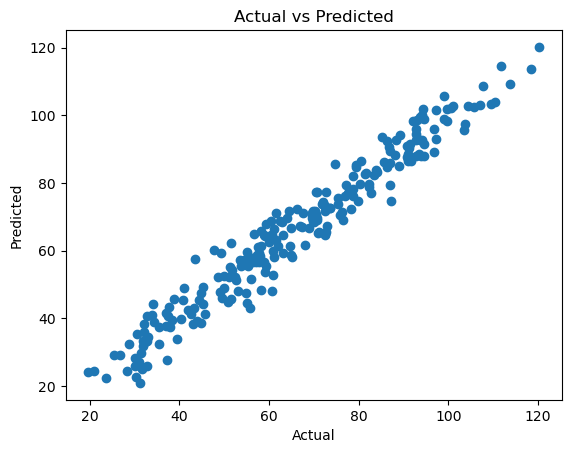

In [21]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

In [22]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results["Error"] = results["Actual"] - results["Predicted"]

results.head(10)

,Actual,Predicted,Error
1178,86.4,84.695917,1.704083
865,69.5,70.416616,-0.916616
101,92.1,98.331943,-6.231943
439,44.3,45.300224,-1.000224
58,30.2,22.551992,7.648008
1120,91.4,91.405837,-0.005837
323,45.2,44.213646,0.986354
974,32.8,33.150769,-0.350769
411,99.1,98.816866,0.283134
855,45.6,41.112377,4.487623


In [23]:
model.score(X_test,y_test)

0.9533676875571129

In [24]:
results["Absolute_Error"] = abs(results["Error"])

results.sort_values("Absolute_Error", ascending=False).head(10)

,Actual,Predicted,Error,Absolute_Error
294,43.5,57.385800,-13.885800,13.885800
1097,55.8,42.907199,12.892801,12.892801
739,60.7,47.934952,12.765048,12.765048
558,87.2,74.681662,12.518338,12.518338
997,47.8,60.201026,-12.401026,12.401026
314,74.8,85.710536,-10.910536,10.910536
415,51.4,62.302468,-10.902468,10.902468
676,55.1,44.481555,10.618445,10.618445
290,31.1,20.849919,10.250081,10.250081
693,34.1,44.129667,-10.029667,10.029667


In [25]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

In [26]:
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [27]:
rf_pred = rf_model.predict(X_test)

In [28]:
rf_model.score(X_test,y_test)

0.9313732456490864

In [29]:
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2:", r2_score(y_test, rf_pred))

MAE: 4.665240238095248
RMSE: 5.929309652225801
R2: 0.9313732456490864


In [30]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("MAE:", -scores.mean())

MAE: 3.9775823972767568


In [32]:
scores_rf = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("MAE:", -scores_rf.mean())

MAE: 4.869228823412702


In [33]:
final_model = model

In [34]:
final_model.fit(X, y)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
import joblib

joblib.dump(final_model, "delivery_eta_model.pkl")

['delivery_eta_model.pkl']

In [36]:
%pip install uvicorn fastapi


   ---------------- ----------------------- 2/5 [uvicorn]
   ------------------------ --------------- 3/5 [starlette]
   -------------------------------- ------- 4/5 [fastapi]
   -------------------------------- ------- 4/5 [fastapi]
   ---------------------------------------- 5/5 [fastapi]

Note: you may need to restart the kernel to use updated packages.


In [37]:
import sys
print(sys.executable)

C:\Users\vishw\anaconda3\python.exe
